<a href="https://colab.research.google.com/github/eloisemcdonough-tech/A05-pca/blob/main/PCA_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [11]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [ ]:
# Your Phase 1 solution to the problem goes here.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

token_freq[:10]

[('new', 1365),
 ('date', 1202),
 ('get', 1052),
 ('please', 1022),
 ('enron', 927),
 ('like', 923),
 ('2002', 869),
 ('would', 806),
 ('one', 798),
 ('message', 795)]

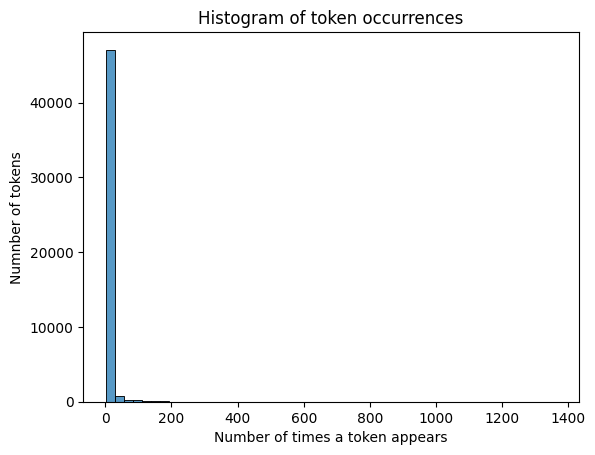

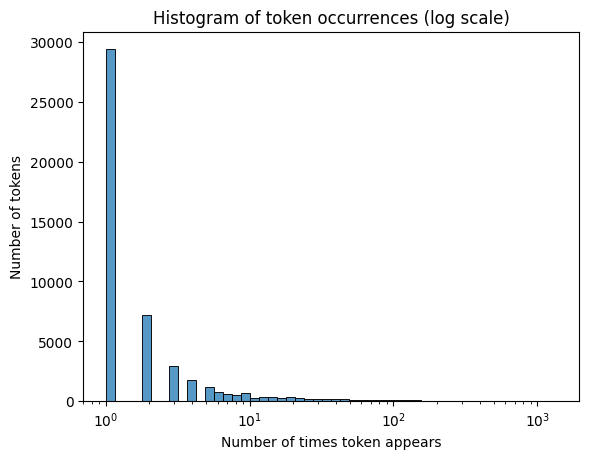

,count
count,48691.000000
mean,5.687889
std,27.717476
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,1365.000000


In [15]:
freq_df=pd.DataFrame(token_freq, columns = ["token", "count"])

sns.histplot(data=freq_df, x="count", bins=50).set(title="Histogram of token occurrences", xlabel = "Number of times a token appears", ylabel = "Numnber of tokens")
plt.show()

sns.histplot(data=freq_df, x = "count", bins = 50, log_scale=True).set(title="Histogram of token occurrences (log scale)", xlabel = "Number of times token appears", ylabel="Number of tokens")
plt.show()

freq_df["count"].describe()

this histogram is very skewed to the right. all the tokens are piled up so you only see a couple words a few times. also only a small portion of tokens show up a thousand times and make a long think tail to the right. the log scale plot is better for this as the number of tokens drops as the count goes up instead of the token frequency being so unequal.

i did this because .most_common shows me the most to least frequent. i put it into a data frame and the histogram shows me how many toekn have each count which is answering the question. i added a log scale becuase the normal scale everything was skewed and using the desrcibe command shows me the numbers to back it up.





In [18]:
df = pd.read_parquet("Phishing_clean.parquet")
print(df.shape)
df.head()

(18634, 2712)


,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [22]:
from sklearn.model_selection import train_test_split

y = df["Email Type"]
X = df.drop(columns=["Email Type"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state = 100)
print(X_train.shape, X_test.shape)

(14907, 2711) (3727, 2711)


80% of the emails are in the training set and 20% are in the test one. the shpes show how the training set has 4 times as many rows as the test set and both have the same columns.

In [24]:
from sklearn.linear_model import LinearRegression
reg = LinearRegression().fit(X_train, y_train)

print ("Train R-squared:", round(reg.score(X_train, y_train), 4))
print("Test R-squared: ", round(reg.score(X_train, y_train), 4))

Train R-squared: 0.768
Test R-squared:  0.768


the training r squared is R-squared is 0.768 and the test group is the same, the model fits the trianing emails well but does not do that well with new emails, which i think means its overfitting. With so many columns the regression has enough numbers to fit the weird things in training emails that dont show up again in the test set.

In [27]:
coefs = pd.Series(reg.coef_, index=X_train.columns)

top = coefs.abs().sort_values(ascending=False).head(20)
coefs[top.index]

,0
background-image:,-0.891476
localized,0.815698
"helvetica,",0.717349
thermal,0.706216
aging,0.622411
transcript,0.578132
april's,-0.546313
retrieving,-0.527824
cnet,-0.510492
zdnet,-0.503465


the words above are the ones with largest coefficients in absolute value, so they move the prediction the most. a postive number would push a prediction towards scam and a negative would push it towards safe. looking at the words though some make sense like xanaax is a misspelling of xanax a which is a common spam thing. but most of the top tokens arent meaningful. other words like thermal and aging and rythem have nothing to do phishing. these are just probably more rare tokens the modle gave large weight to just to fit it in the trianing data which could connect back to the possible overfitting the earlier question.

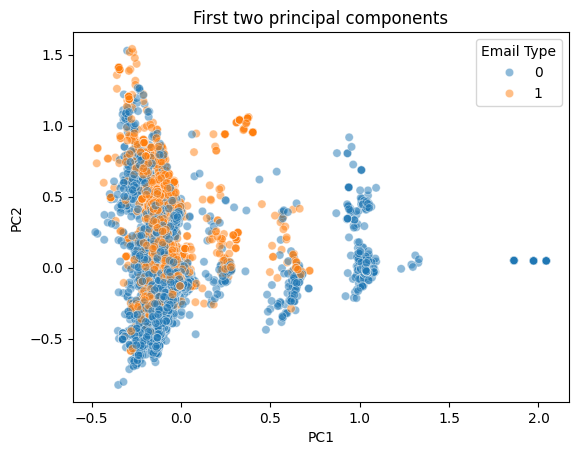

Variance explained [0.011 0.009]


In [30]:
from sklearn.decomposition import PCA

pca = PCA(n_components = 2).fit(X)
X_pca = pca.transform(X)

pca_df = pd.DataFrame(X_pca, columns = ["PC1", "PC2"])
pca_df["Email Type"] = y.values

sns.scatterplot(data=pca_df, x="PC1", y= "PC2", hue="Email Type", alpha = 0.5).set(title="First two principal components")
plt.show()

print("Variance explained", pca.explained_variance_ratio_.round(3))


the scam and non scamemails are partly seperated. The two colors are placed in different parts along pc1 however theres is a huge overlapping chunck closer to 0.5 pc1. the middle of the graph they are pretty mixed too,m not until 1 do we only see the blue dots seperated. the variance explained is small which makes sense becasue of only having two components try and summerize thousands of word columns.

In [31]:
pca_big = PCA(n_components = 2610).fit(X_train)


Z_train = pca_big.transform(X_train)
Z_test = pca_big.fit_transform(X_test)

reg_pca = LinearRegression().fit(Z_train, y_train)

print("Train R-squared:", round(reg_pca.score(Z_train, y_train), 4))
print("Test R-squared: ", round(reg_pca.score(Z_test, y_test), 4))

Train R-squared: 0.7673
Test R-squared:  -0.8519


the training r squared is 0.7673 and the testr squared is -0.8519. compared to the previous regression. the trianing is slightly lower but the test one is much lower and negative. there is still a big gap between the two numbers. the principal components model fits the trianing emails but predicts new emails worse than just guessing the an average. so i think its still overfitting and not doing a better job thsn the test set.

i have seen that a lot of columsn overlap because of multiple emails giving the models the same information more than once. Thsi results in the data being skewed with large weird coefficients. I saw this in question 2.3. Its like the dummy variable trap we learned in class where columns that are overkaping tend to cause problems with results. PCA helps because it takes the overlapping columns and puts the overlapping words into new columns. So now they dont overlap with eachother at all. They are alsp ordered and sorted in a very helpful way, so the useful information stays at the top while the data that is just noise is dropped. The model should overfit less and do a better job on emails it hasnt seen before.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]